In [1]:
!pip install -q ultralytics opencv-python-headless

In [2]:
%pip install --upgrade sympy

In [3]:
import torch
import cv2
import ultralytics

print("YOLO version:", ultralytics.__version__)
print("OpenCV version:", cv2.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

YOLO version: 8.4.183
OpenCV version: 4.14.0
GPU available: True
GPU name: Tesla T4


In [4]:
from ultralytics import YOLO

# Loading a small pretrained YOLO model
model = YOLO("yolo11n.pt")

print("YOLO model loaded successfully!")

YOLO model loaded successfully!


In [5]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle (1).json


In [6]:


!pip install -q kaggle

import os
import shutil

# Creating a folder for Kaggle credentials
os.makedirs("/root/.kaggle", exist_ok=True)

# Copying the uploaded key into that folder
shutil.copy(
    "/content/kaggle.json",
    "/root/.kaggle/kaggle.json"
)

# Protecting the credentials file
os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle configured successfully!")



Kaggle configured successfully!


In [7]:


!mkdir -p /content/drone_dataset

!kaggle datasets download \
    -d cybersimar08/drone-detection \
    -p /content/drone_dataset \
    --unzip


Dataset URL: https://www.kaggle.com/datasets/cybersimar08/drone-detection
License(s): CC0-1.0
100% 499M/499M [00:10<00:00, 49.2MB/s]



In [8]:


import os

dataset_path = "/content/drone_dataset"

print("Dataset folder exists:", os.path.exists(dataset_path))

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")
        for file in files[:10]:
            print("  " * (level + 1) + file)

Dataset folder exists: True
drone_dataset/
  tensorflow obj detection drone/
    README.dataset.txt
    README.roboflow.txt
    test/
      V_DRONE_099209_119_png.rf.48ae13a5208400ffa7fef16fb99d2396.jpg
      V_AIRPLANE_05656_299_png.rf.606834108b4951c9eacb5de047532988.jpg
      V_AIRPLANE_02828_198_png.rf.bf683abb7c630d3b5116575453991828.jpg
      V_DRONE_075185_050_png.rf.993d75a0c1b64d181703b28cd0678c82.jpg
      V_BIRD_047106_040_png.rf.618e53bacde9fd6f8f945c771f641dd8.jpg
      V_AIRPLANE_02828_133_png.rf.b5795c564f6a6ef01414228327369b83.jpg
      V_HELICOPTER_023247_312_png.rf.a4363e61ce8734773298c477bf7c36ef.jpg
      V_BIRD_00867_158_png.rf.6ce52254332b028a8bafb709691f9e5e.jpg
      V_DRONE_082192_155_png.rf.704a8c9c10637284f3a54d466c9af177.jpg
      V_AIRPLANE_0088_130_png.rf.856d4f0a63eb2332729ed21b5d127279.jpg
    valid/
      V_HELICOPTER_052276_142_png.rf.e351ecba90a3e7c9d21719fb03cd6090.jpg
      V_DRONE_017127_194_png.rf.f9547dc11a4bdaaf85ac81ec20e88aab.jpg
      V_DRONE

In [9]:

import os

dataset_root = "/content/drone_dataset"

for root, dirs, files in os.walk(dataset_root):
    if "data.yaml" in files:
        print("Found YOLO configuration:")
        print(os.path.join(root, "data.yaml"))


Found YOLO configuration:
/content/drone_dataset/drone-detection-new.v5-new-train.yolov8/data.yaml


In [10]:

import yaml

yaml_path = (
    "/content/drone_dataset/"
    "drone-detection-new.v5-new-train.yolov8/data.yaml"
)

with open(yaml_path, "r") as f:
    config = yaml.safe_load(f)

print(config)


{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 3, 'names': ['AirPlane', 'Drone', 'Helicopter'], 'roboflow': {'workspace': 'ahmedmohsen', 'project': 'drone-detection-new-peksv', 'version': 5, 'license': 'MIT', 'url': 'https://universe.roboflow.com/ahmedmohsen/drone-detection-new-peksv/dataset/5'}}


In [11]:
import yaml
import os

dataset_dir = "/content/drone_dataset/drone-detection-new.v5-new-train.yolov8"

config = {
    "path": dataset_dir,
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 3,
    "names": ["AirPlane", "Drone", "Helicopter"]
}

yaml_path = "/content/drone_data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print(open(yaml_path).read())

path: /content/drone_dataset/drone-detection-new.v5-new-train.yolov8
train: train/images
val: valid/images
test: test/images
nc: 3
names:
- AirPlane
- Drone
- Helicopter



In [12]:


import os

for split in ["train", "valid", "test"]:
    image_dir = os.path.join(dataset_dir, split, "images")
    label_dir = os.path.join(dataset_dir, split, "labels")

    images = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    labels = [
        f for f in os.listdir(label_dir)
        if f.endswith(".txt")
    ]

    print(f"{split}:")
    print("  Images:", len(images))
    print("  Label files:", len(labels))



train:
  Images: 10799
  Label files: 10799
valid:
  Images: 603
  Label files: 603
test:
  Images: 596
  Label files: 596


In [15]:

from ultralytics import YOLO

# Load a small pretrained YOLO model
model = YOLO("yolo11n.pt")

# Train it on the drone dataset
results = model.train(
    data=yaml_path,
    epochs=5,
    imgsz=640,
    batch=4,
    device=0,
    patience=8,
    project="/content/drone_runs",
    name="drone_detection_v2"
)


Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drone_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=drone_detection_v2-2, nbs=64, nms=None, opset=None, optimize=False

['confusion_matrix_normalized.png', 'BoxR_curve.png', 'confusion_matrix.png', 'BoxPR_curve.png', 'BoxF1_curve.png', 'args.yaml', 'train_batch2.jpg', 'val_batch2_pred.jpg', 'val_batch1_pred.jpg', 'val_batch1_labels.jpg', 'results.png', 'BoxP_curve.png', 'train_batch0.jpg', 'val_batch2_labels.jpg', 'val_batch0_pred.jpg', 'results.csv', 'weights', 'train_batch1.jpg', 'val_batch0_labels.jpg', 'labels.jpg']


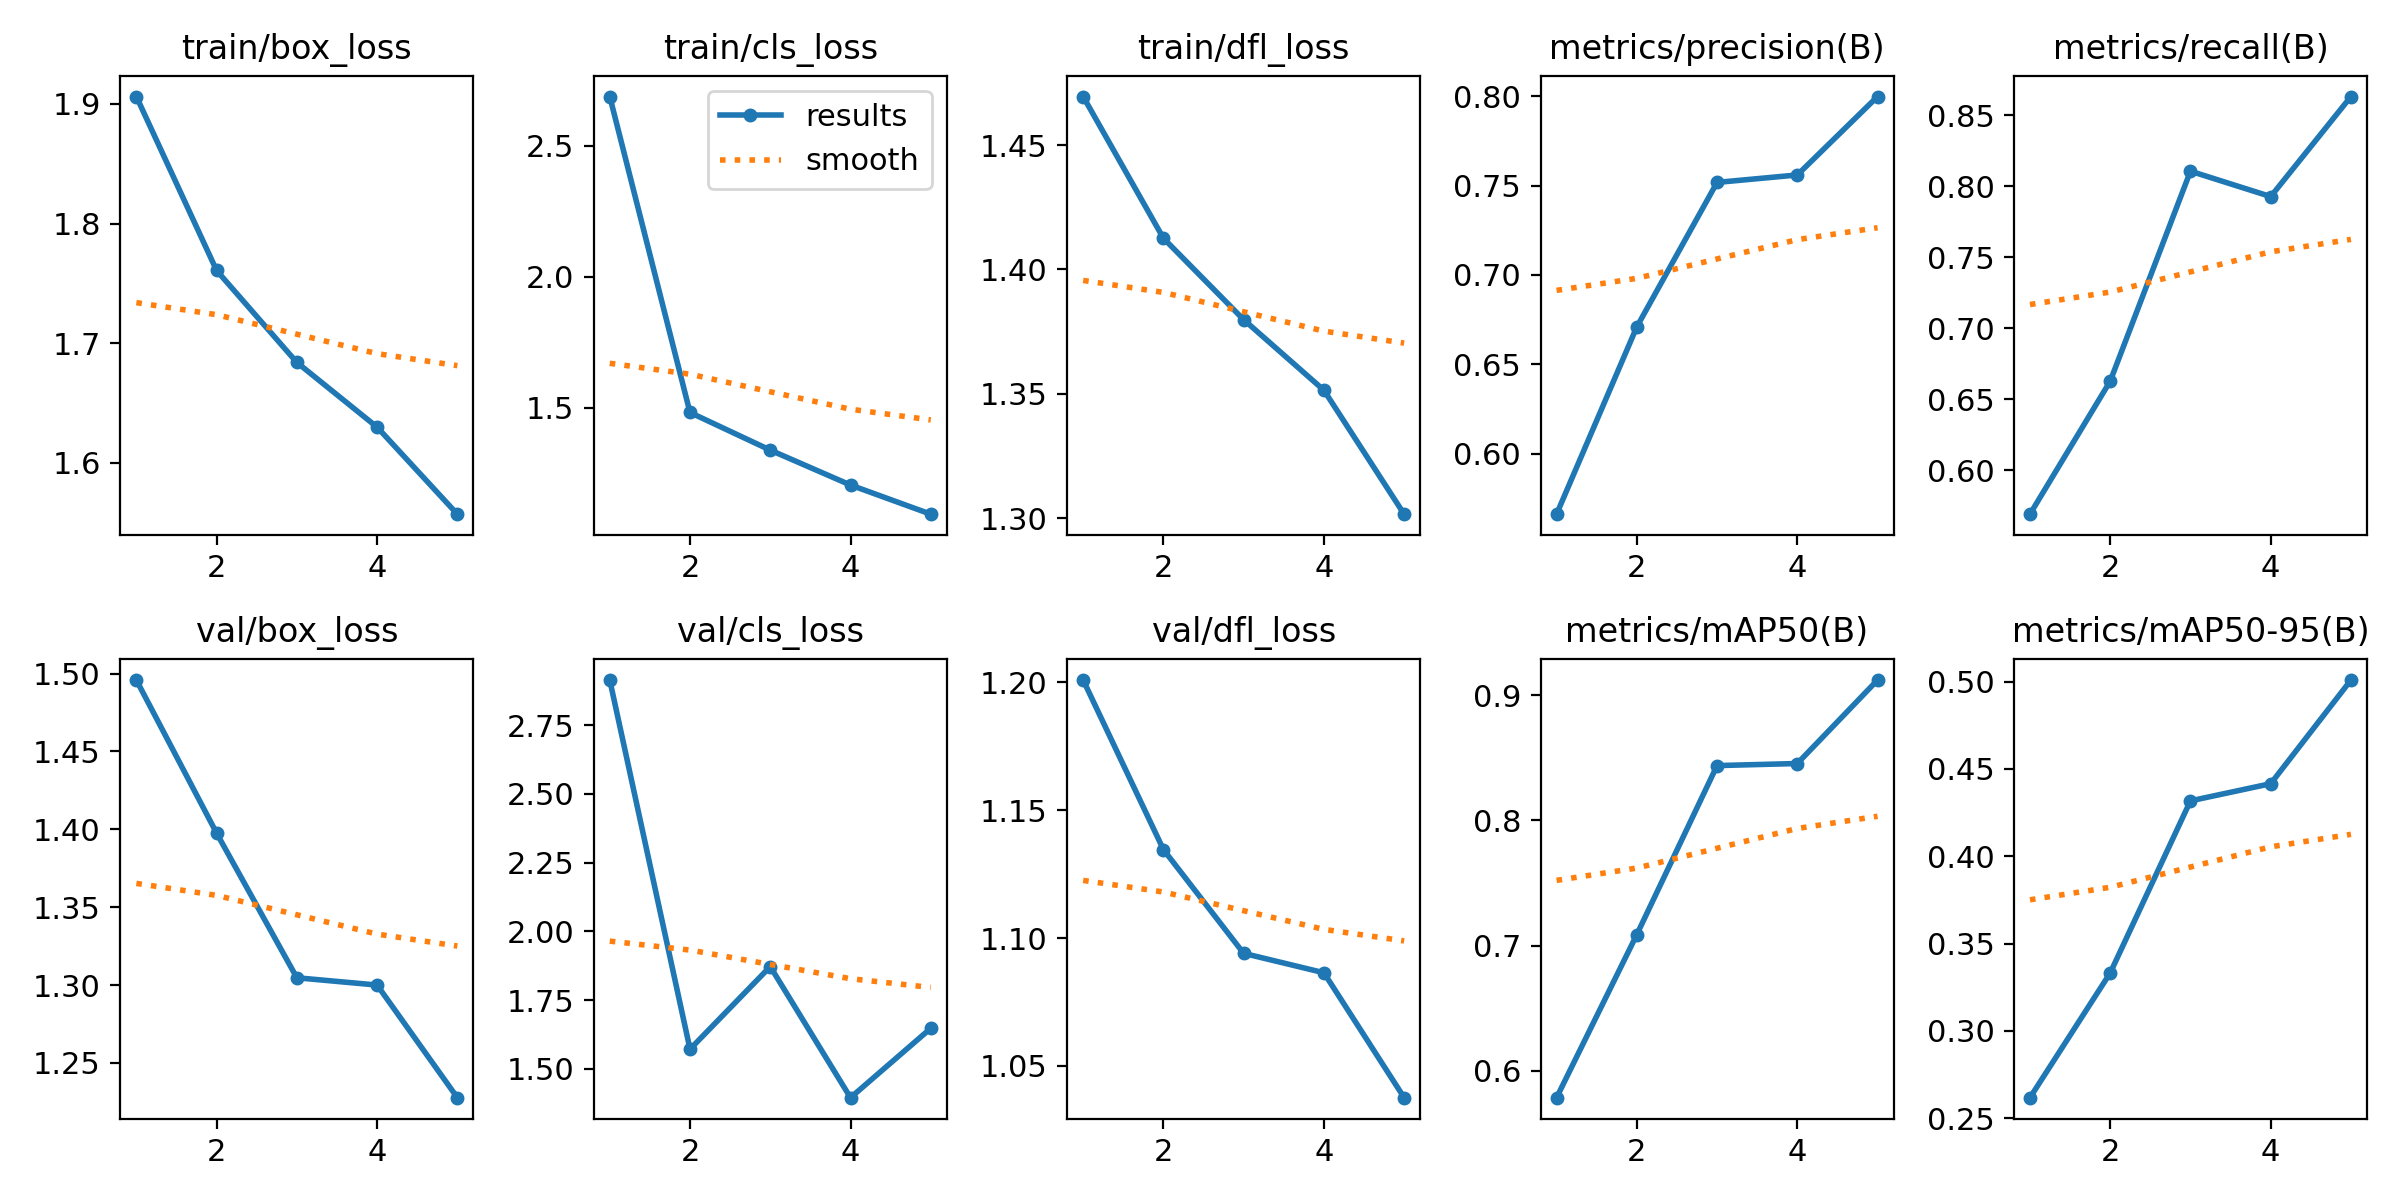

In [22]:
import os
from IPython.display import Image, display

folder = "/content/drone_runs/drone_detection_v2-2"

print(os.listdir(folder))
display(Image(filename="/content/drone_runs/drone_detection_v2-2/results.png"))

In [23]:
import os

print(os.listdir("/content/drone_runs/drone_detection_v2-2/weights"))

['best.pt', 'last.pt']


In [24]:
from google.colab import drive
import shutil

drive.mount("/content/drive")

shutil.copy(
    "/content/drone_runs/drone_detection_v2-2/weights/best.pt",
    "/content/drive/MyDrive/best.pt"
)

print("Model saved to Google Drive!")

Mounted at /content/drive
Model saved to Google Drive!


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [27]:
import os
import shutil

source = "/content/drone_runs/drone_detection_v2-2/weights/best.pt"
destination = "/content/drive/MyDrive/best.pt"

# Copy the trained model to Google Drive
shutil.copy2(source, destination)

print("Model saved:", os.path.exists(destination))
print("Model size:", round(os.path.getsize(destination) / (1024 * 1024), 2), "MB")

Model saved: True
Model size: 5.25 MB


In [5]:
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/best.pt")

print("Model loaded successfully!")
print("Classes:", model.names)


Model loaded successfully!
Classes: {0: 'AirPlane', 1: 'Drone', 2: 'Helicopter'}


In [6]:
from google.colab import files

uploaded = files.upload()

Saving Screenshot 2026-10-20 at 6.20.06 PM.png to Screenshot 2026-10-20 at 6.20.06 PM (1).png



image 1/1 /content/Screenshot 2026-10-20 at 6.20.06 PM (1).png: 480x640 1 AirPlane, 2 Helicopters, 8.9ms
Speed: 37.5ms preprocess, 8.9ms inference, 20.9ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/runs/detect/predict-2
Saved files: ['/content/runs/detect/predict/Screenshot 2026-10-20 at 6.11.24\u202fPM.jpg', '/content/runs/detect/predict/Screenshot 2026-10-20 at 6.18.49\u202fPM.jpg', '/content/runs/detect/predict/Screenshot 2026-10-20 at 6.10.33\u202fPM.jpg', '/content/runs/detect/predict/Screenshot 2026-10-20 at 6.09.42\u202fPM.jpg', '/content/runs/detect/predict/Screenshot 2026-10-20 at 6.20.06\u202fPM.jpg', '/content/runs/detect/predict/Screenshot 2026-10-20 at 6.06.20\u202fPM.jpg']


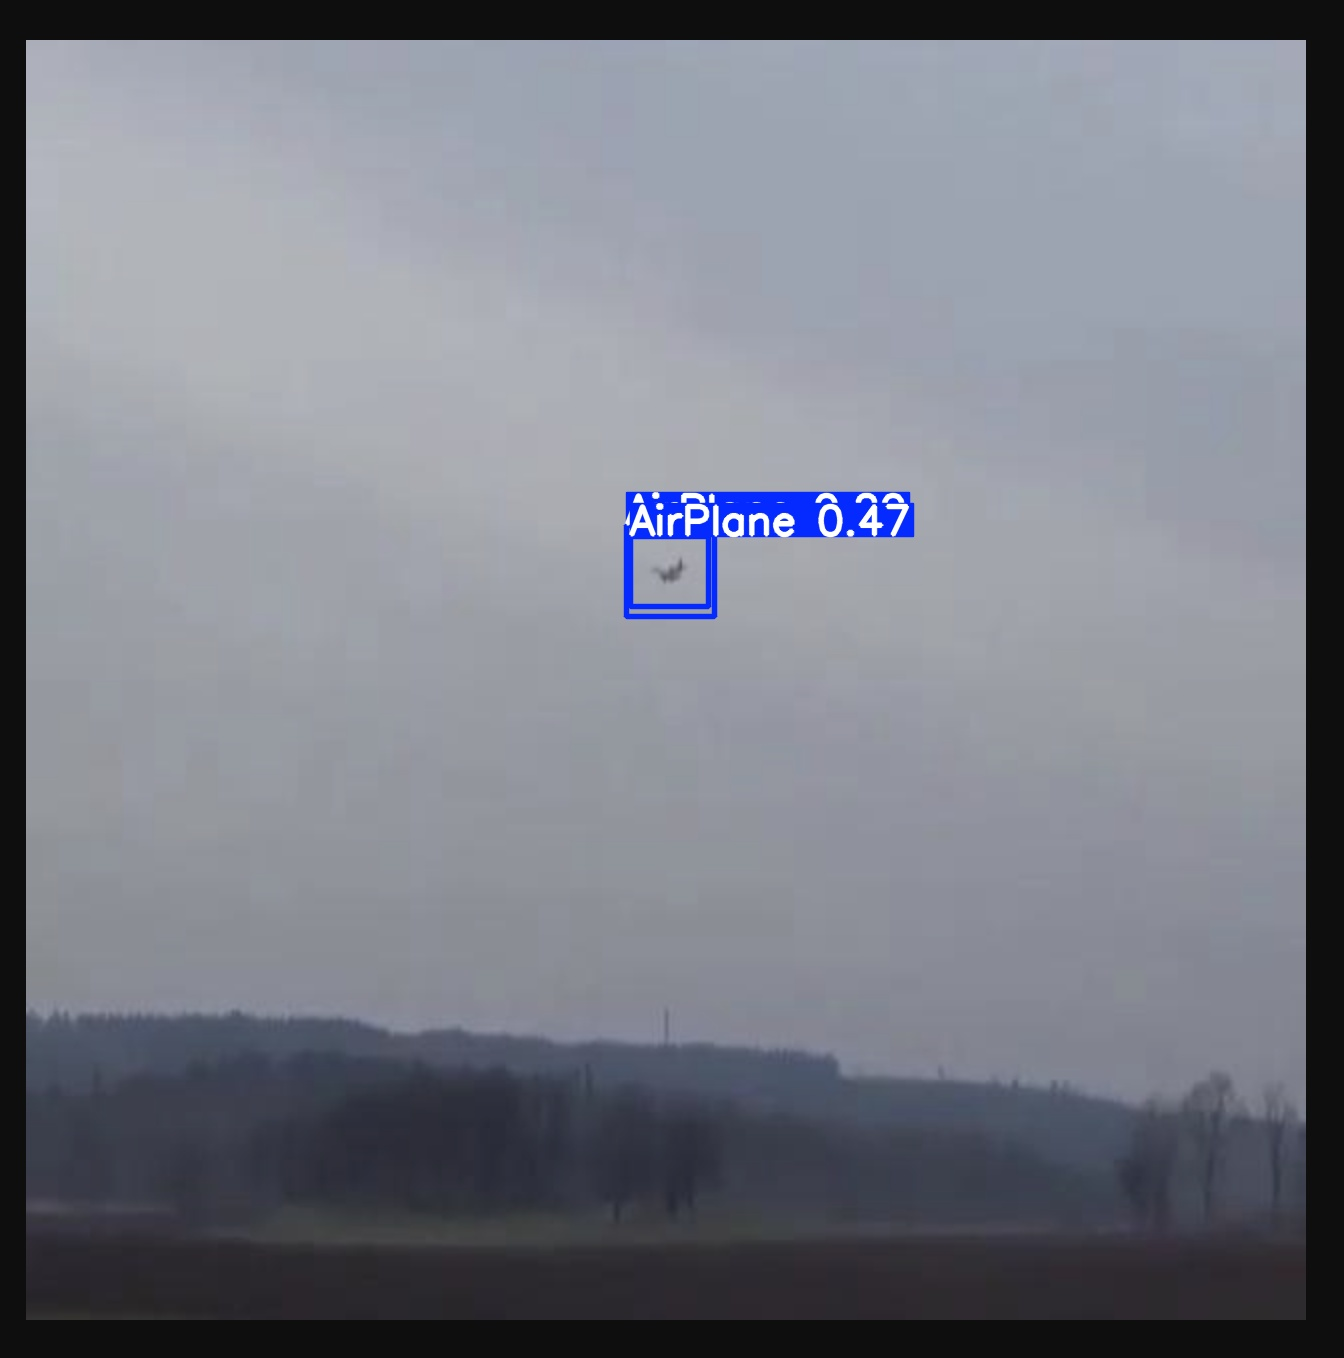

In [7]:
from IPython.display import display, Image
import glob
import os

import os
from IPython.display import display, Image

image_path = next(iter(uploaded.keys()))

results = model.predict(
    source=image_path,
    conf=0.10,
    save=True
)
saved_images = glob.glob("/content/runs/detect/predict/*")

print("Saved files:", saved_images)

if saved_images:
    display(Image(filename=saved_images[0]))

In [10]:
from google.colab import files

uploaded_video = files.upload()

Saving 27363-363524166.mp4 to 27363-363524166.mp4


In [11]:
import os
from ultralytics import YOLO

# Loading the trained model from Google Drive
model = YOLO("/content/drive/MyDrive/best.pt")

# Get the uploaded video filename
video_path = next(iter(uploaded_video.keys()))

# Tracking objects throughout the video
results = model.track(
    source=video_path,
    conf=0.10,
    tracker="bytetrack.yaml",
    persist=True,
    save=True,
    project="/content/drone_tracking",
    name="tracked_video"
)

print("Tracking finished!")

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 254ms
Prepared 1 package in 48ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/300) /content/27363-363524166.mp4: 384x640 2 Helicopters, 13.9ms
video 1/1 (frame 2

In [12]:
import cv2
import pandas as pd
import torch

device = 0 if torch.cuda.is_available() else "cpu"

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise ValueError("Error.Could not open video.")

records = []
previous_centres = {}

while True:
    success, frame = cap.read()

    if not success:
        break

    result = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        conf=0.10,
        classes=[1],  # Drone class in the provided dataset
        device=device,
        verbose=False
    )[0]

    if result.boxes is not None and len(result.boxes) > 0:
        for i, box in enumerate(result.boxes):
            x1, y1, x2, y2 = box.xyxy[0].cpu().tolist()

            centre_x = (x1 + x2) / 2
            centre_y = (y1 + y2) / 2

            track_id = -1
            if box.id is not None:
                track_id = int(box.id.item())

            previous = previous_centres.get(track_id)

            if previous is None:
                change_x = 0
                change_y = 0
            else:
                change_x = centre_x - previous[0]
                change_y = centre_y - previous[1]

            previous_centres[track_id] = (centre_x, centre_y)

            records.append({
                "track_id": track_id,
                "centre_x": centre_x,
                "centre_y": centre_y,
                "change_x": change_x,
                "change_y": change_y
            })

cap.release()

positions = pd.DataFrame(records)
display(positions.head(10))

print("Total tracked detections:", len(positions))

""


Total tracked detections: 0
